### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import json
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    RandomizedSearchCV
)
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    LSTM,
    GRU,
    Bidirectional,
    Conv1D,
    MaxPooling1D
)
from tensorflow.keras.callbacks import EarlyStopping
from xgboost import XGBRegressor
from pathlib import Path

### Loading dataset

In [2]:
df = pd.read_csv(
    "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=[
        "engine_id", "cycle",
        "setting_1", "setting_2", "setting_3",
        "sensor_1", "sensor_2", "sensor_3", "sensor_4", "sensor_5",
        "sensor_6", "sensor_7", "sensor_8", "sensor_9", "sensor_10",
        "sensor_11", "sensor_12", "sensor_13", "sensor_14", "sensor_15",
        "sensor_16", "sensor_17", "sensor_18", "sensor_19", "sensor_20",
        "sensor_21"
    ]
)

### Understanding the dataset

In [3]:
df.shape

(20631, 26)

In [4]:
df.dtypes

engine_id      int64
cycle          int64
setting_1    float64
setting_2    float64
setting_3    float64
sensor_1     float64
sensor_2     float64
sensor_3     float64
sensor_4     float64
sensor_5     float64
sensor_6     float64
sensor_7     float64
sensor_8     float64
sensor_9     float64
sensor_10    float64
sensor_11    float64
sensor_12    float64
sensor_13    float64
sensor_14    float64
sensor_15    float64
sensor_16    float64
sensor_17      int64
sensor_18      int64
sensor_19    float64
sensor_20    float64
sensor_21    float64
dtype: object

In [5]:
df.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [6]:
df.isna().sum()

engine_id    0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['engine_id'].unique() #finding total engines

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100])

In [9]:
df['cycle'].unique() # finding total and unique cycles in the dataset

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

In [10]:
df.head(362) # checking if each engine has max cycles i.e. 362

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
357,2,166,-0.0068,0.0002,100.0,518.67,641.79,1589.09,1394.26,14.62,...,521.96,2388.01,8142.11,8.4111,0.03,392,2388,100.0,38.87,23.4352
358,2,167,0.0005,-0.0001,100.0,518.67,642.25,1588.74,1395.35,14.62,...,522.11,2388.03,8148.57,8.4261,0.03,393,2388,100.0,38.84,23.3977
359,2,168,-0.0026,-0.0003,100.0,518.67,642.55,1593.95,1404.01,14.62,...,521.89,2388.04,8135.51,8.4329,0.03,391,2388,100.0,38.84,23.3787
360,2,169,-0.0004,0.0003,100.0,518.67,642.26,1581.85,1406.06,14.62,...,521.77,2388.09,8141.96,8.4214,0.03,391,2388,100.0,38.93,23.3766


In [11]:
engine_cycles = df.groupby('engine_id')['cycle'].max() # finding total cycles for each engine
engine_cycles

engine_id
1      192
2      287
3      179
4      189
5      269
      ... 
96     336
97     202
98     156
99     185
100    200
Name: cycle, Length: 100, dtype: int64

In [12]:
df = df.sort_values(['engine_id','cycle']).reset_index(drop=True) 
# sorting the engines chronologically based on cycles
# reset the indexing if after sorting the index changes 
df.tail()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640
20630,100,200,-0.0032,-0.0005,100.0,518.67,643.85,1600.38,1432.14,14.62,...,519.30,2388.26,8137.33,8.5036,0.03,396,2388,100.0,38.37,23.0522


In [13]:
df.describe()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


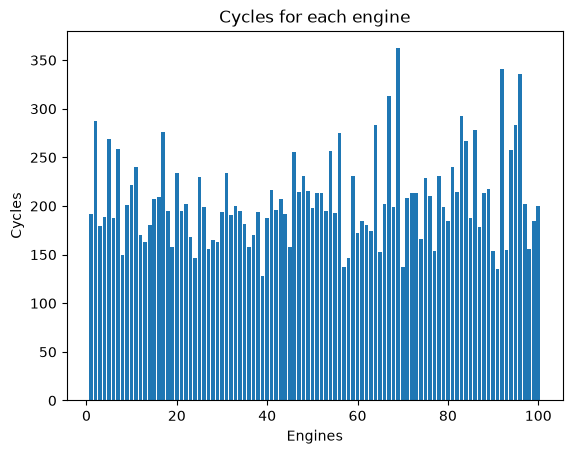

In [14]:
plt.bar(engine_cycles.index,engine_cycles.values)
plt.title("Cycles for each engine")
plt.xlabel("Engines")
plt.ylabel("Cycles")
plt.show()

### Removing Constant Sensors

In [15]:
sensor_data = df.drop(['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3'], axis=1)
sensors = [c for c in df.columns if c.startswith('sensor_')]
sensor_data.describe()

,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,21.609803,553.367711,2388.096652,9065.242941,1.3,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,0.00,0.500053,6.131150,9.000605,5.329200e-15,0.001389,0.885092,0.070985,22.082880,0.0,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,21.600000,549.850000,2387.900000,9021.730000,1.3,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,21.610000,552.810000,2388.050000,9053.100000,1.3,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,21.610000,553.440000,2388.090000,9060.660000,1.3,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,21.610000,554.010000,2388.140000,9069.420000,1.3,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,21.610000,556.060000,2388.560000,9244.590000,1.3,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


In [16]:
constant_columns = [c for c in sensor_data if df[c].min() == df[c].max()]
# finding the sensor columns whose data is constant accross all  cycles
df = df.drop(columns=constant_columns) # dropping them, since they dont provide any variation in data
df.columns

Index(['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_2',
       'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9',
       'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15',
       'sensor_17', 'sensor_20', 'sensor_21'],
      dtype='str')

### Analysing sensor behaviour

In [17]:
sensor_data = df.drop(['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3'], axis=1)
# rebuilding sensor_data after dropping constant columns 
sensors = [c for c in df.columns if c.startswith('sensor_')]
sensor_data.head()

,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442
3,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739
4,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044


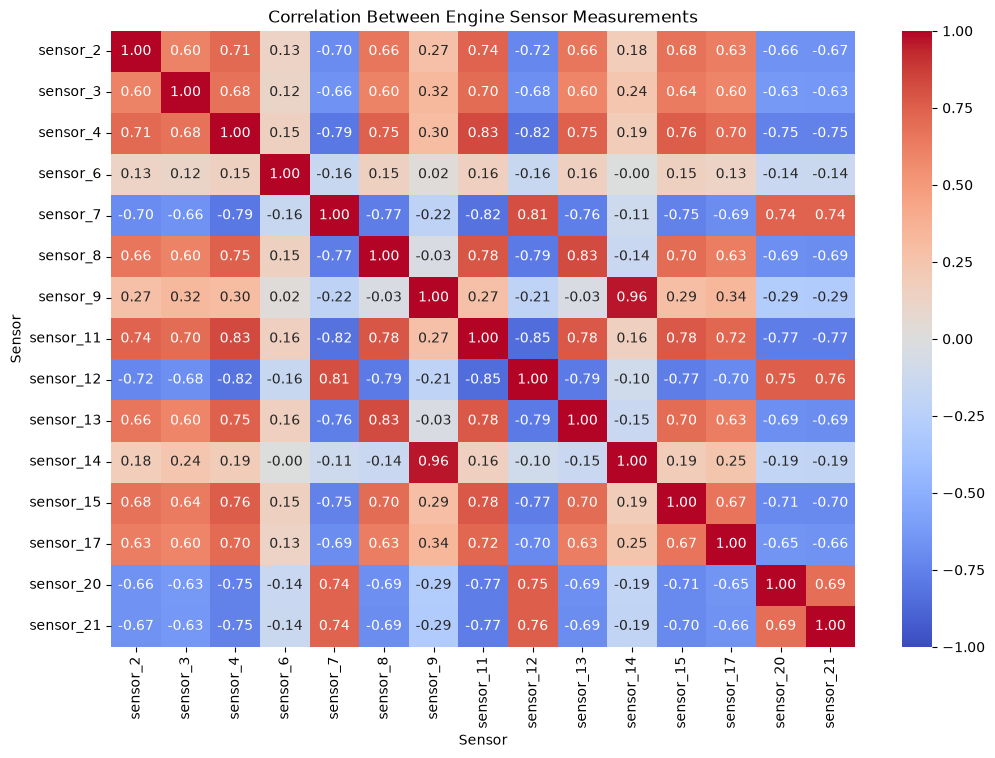

In [18]:
plt.figure(figsize=(12,8))
sns.heatmap(sensor_data.corr(),cmap="coolwarm", annot=True, fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Between Engine Sensor Measurements")
plt.xlabel("Sensor")
plt.ylabel("Sensor")
plt.show()

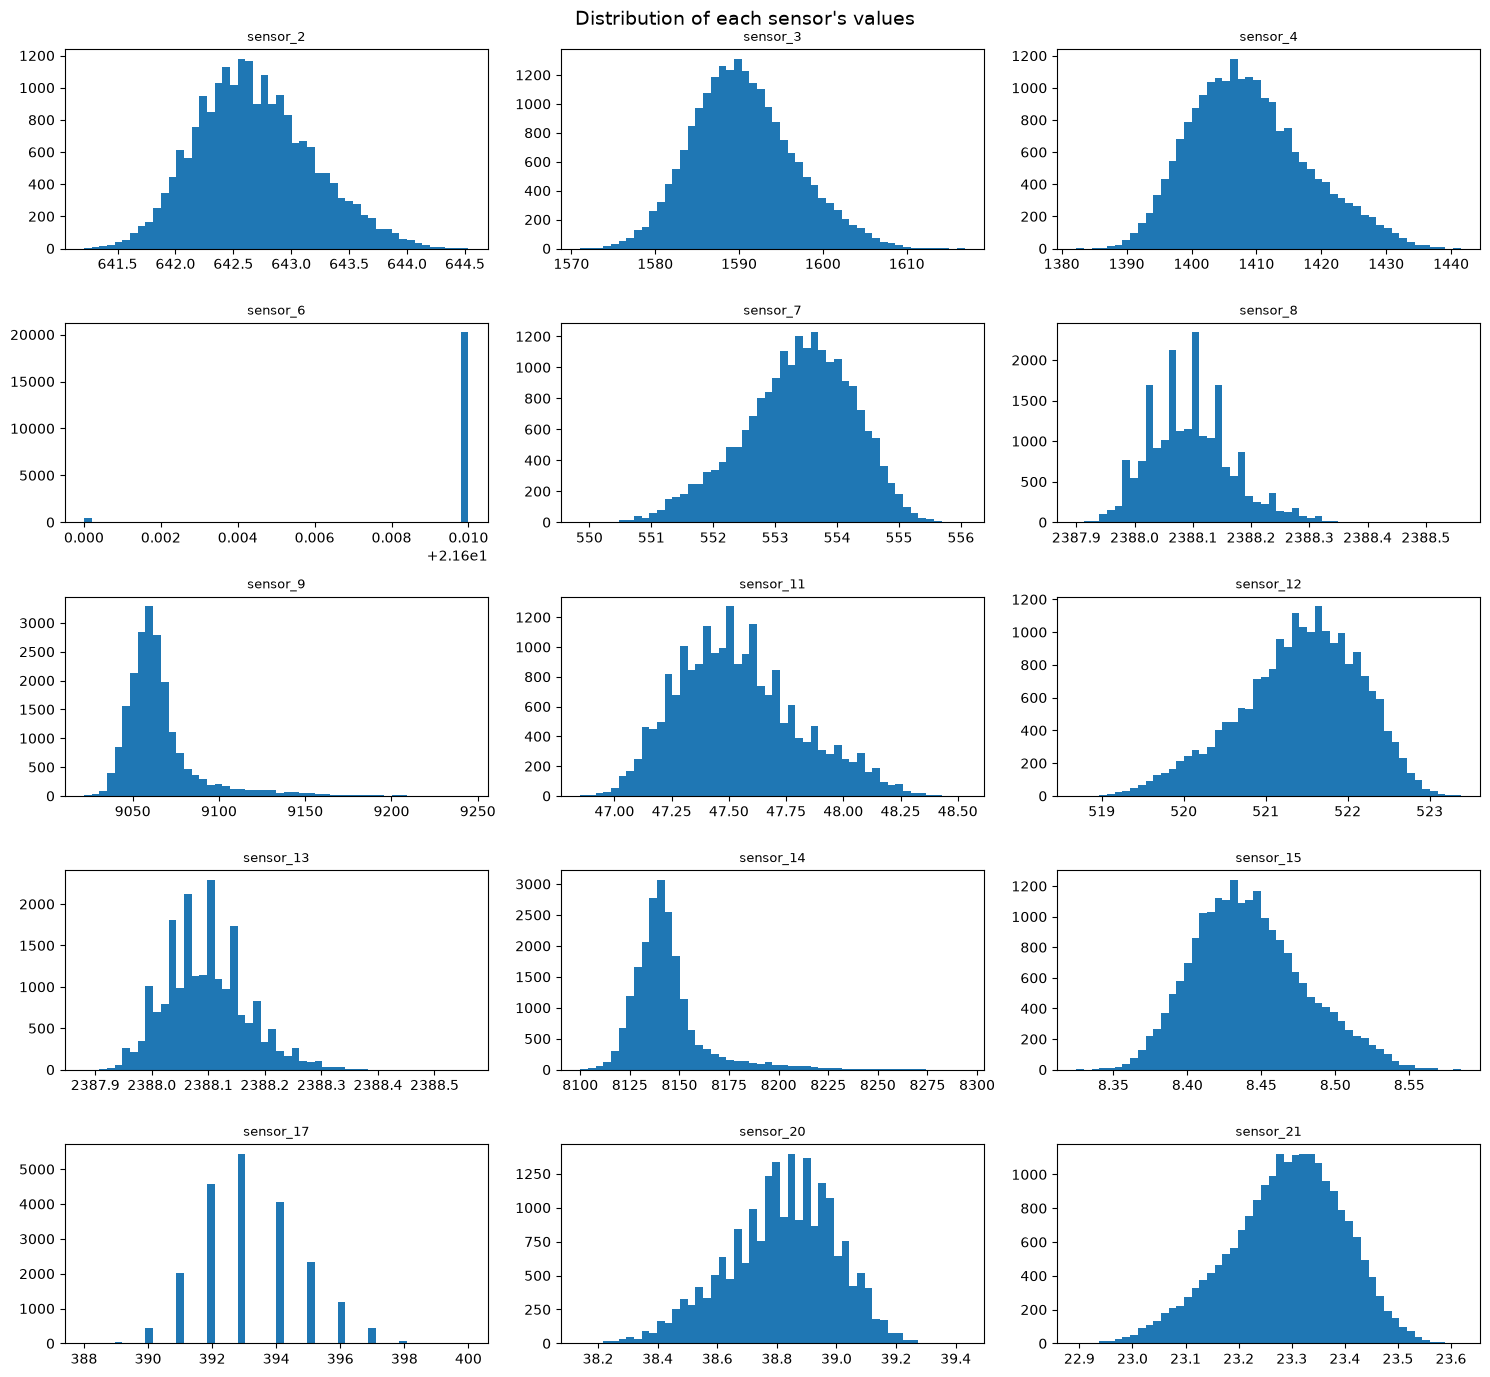

In [19]:
fig, axes = plt.subplots(5,3, figsize=(15,14))
for ax, s in zip(axes.flat, sensors):
    ax.hist(df[s],bins=50)
    ax.set_title(s,fontsize=9)
fig.suptitle("Distribution of each sensor's values", fontsize=14)
plt.tight_layout()
plt.show()

In [20]:
engine1 = df[df['engine_id'] == 1]
engine1

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,1,188,-0.0067,0.0003,100.0,643.75,1602.38,1422.78,21.61,551.94,2388.31,9037.91,48.00,519.79,2388.23,8117.69,8.5207,396,38.51,22.9588
188,1,189,-0.0006,0.0002,100.0,644.18,1596.17,1428.01,21.61,550.70,2388.27,9044.55,48.08,519.58,2388.33,8117.51,8.5183,395,38.48,23.1127
189,1,190,-0.0027,0.0001,100.0,643.64,1599.22,1425.95,21.61,551.29,2388.29,9040.58,48.33,520.04,2388.35,8112.58,8.5223,398,38.49,23.0675
190,1,191,-0.0000,-0.0004,100.0,643.34,1602.36,1425.77,21.61,550.92,2388.28,9042.76,48.15,519.57,2388.30,8114.61,8.5174,394,38.45,23.1295


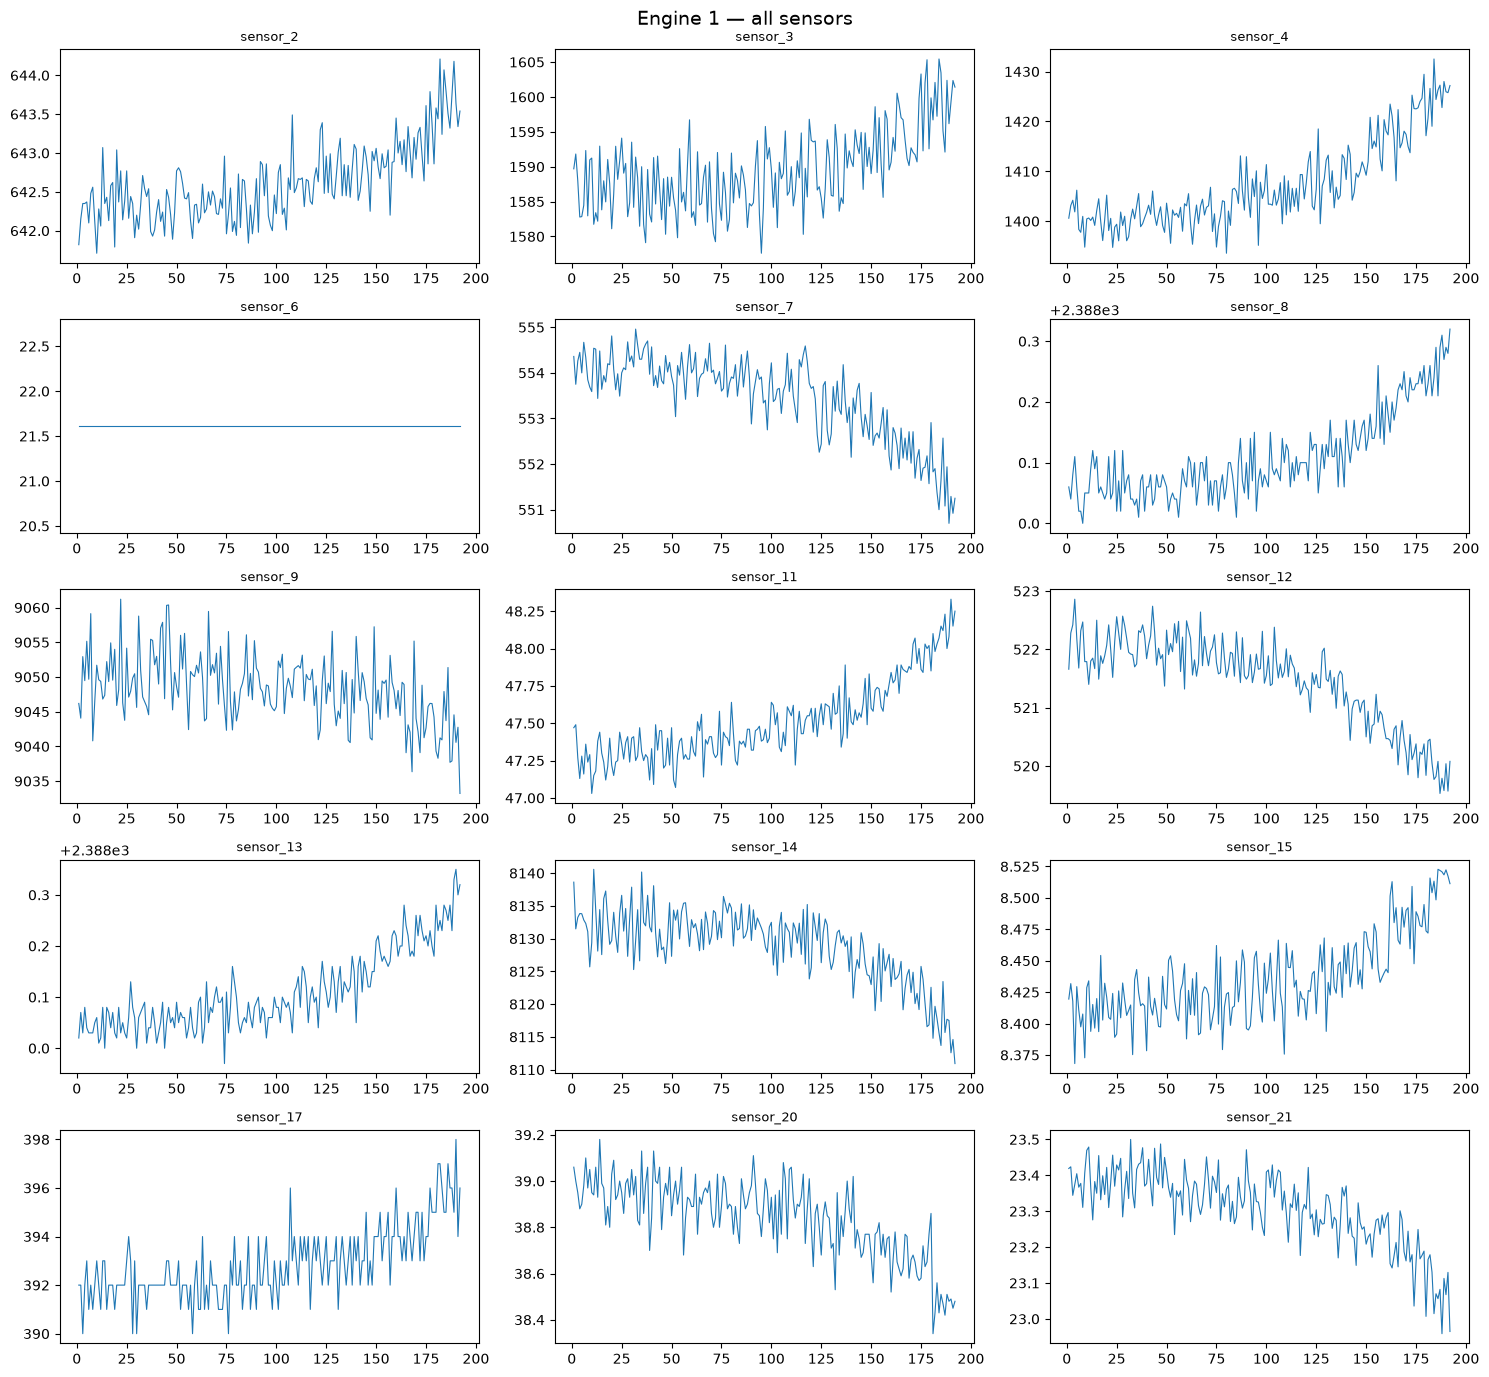

In [21]:
fig, axes = plt.subplots(5, 3, figsize=(15, 14))
for ax, s in zip(axes.flat, sensors):
    ax.plot(engine1['cycle'], engine1[s], linewidth=0.8)
    ax.set_title(s, fontsize=9)
fig.suptitle('Engine 1 — all sensors', fontsize=14)
plt.tight_layout()
plt.show()

### Calulating Remaining Useful Life (RUL)

In [22]:
df['RUL'] = df.groupby('engine_id')['cycle'].transform('max') - df['cycle']

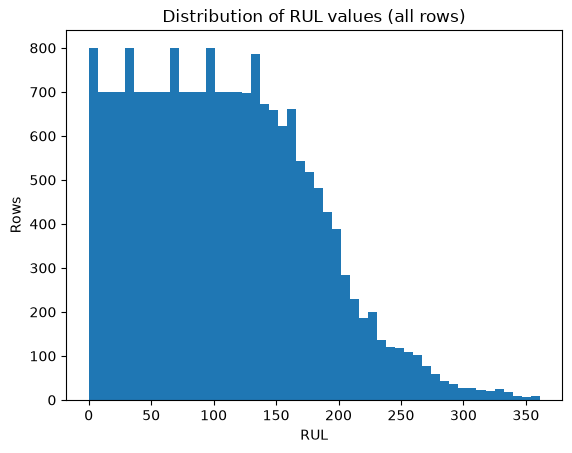

In [23]:
plt.hist(df['RUL'], bins=50)
plt.title("Distribution of RUL values (all rows)")
plt.xlabel("RUL")
plt.ylabel("Rows")
plt.show()

In [24]:
sensor_data.isna().sum()

sensor_2     0
sensor_3     0
sensor_4     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_17    0
sensor_20    0
sensor_21    0
dtype: int64

In [25]:
sensor_data.duplicated().sum()

np.int64(0)

### Preprocessing for test_fd001

In [26]:
df_test = pd.read_csv(
    "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=[
        "engine_id", "cycle",
        "setting_1", "setting_2", "setting_3",
        "sensor_1", "sensor_2", "sensor_3", "sensor_4", "sensor_5",
        "sensor_6", "sensor_7", "sensor_8", "sensor_9", "sensor_10",
        "sensor_11", "sensor_12", "sensor_13", "sensor_14", "sensor_15",
        "sensor_16", "sensor_17", "sensor_18", "sensor_19", "sensor_20",
        "sensor_21"
    ]
)
df_test.shape

(20631, 26)

In [27]:
df.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,...,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,21.61,554.36,...,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,21.61,553.75,...,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,21.61,554.26,...,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,21.61,554.45,...,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,21.61,554.00,...,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,187


In [28]:
df_test.isna().sum()

engine_id    0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
dtype: int64

In [29]:
df_test.duplicated().sum()

np.int64(0)

In [30]:
df_test['engine_id'].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100])

In [31]:
df_test['cycle'].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

In [32]:
engine_cycles_test = df.groupby('engine_id')['cycle'].max()
engine_cycles_test

engine_id
1      192
2      287
3      179
4      189
5      269
      ... 
96     336
97     202
98     156
99     185
100    200
Name: cycle, Length: 100, dtype: int64

In [33]:
df_test = df_test.sort_values(['engine_id','cycle']).reset_index(drop=True) 
# sorting the engines chronologically based on cycles
# reset the indexing if after sorting the index changes 
df_test.tail()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640
20630,100,200,-0.0032,-0.0005,100.0,518.67,643.85,1600.38,1432.14,14.62,...,519.30,2388.26,8137.33,8.5036,0.03,396,2388,100.0,38.37,23.0522


In [34]:
df_test.describe()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


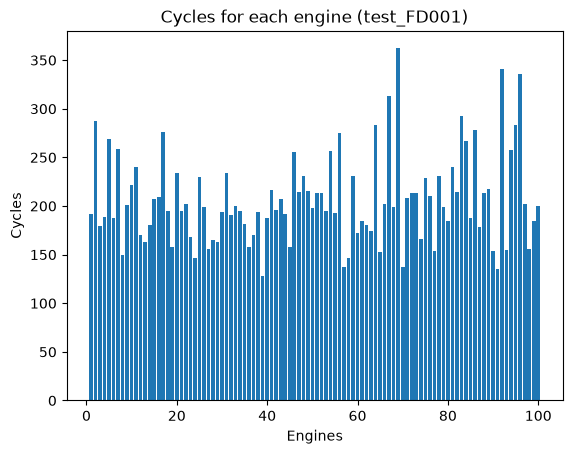

In [35]:
plt.bar(engine_cycles_test.index,engine_cycles_test.values)
plt.title("Cycles for each engine (test_FD001)")
plt.xlabel("Engines")
plt.ylabel("Cycles")
plt.show()

In [36]:
constant_columns_test = [c for c in sensor_data if df_test[c].min() == df_test[c].max()]
# finding the sensor columns whose data is constant accross all  cycles
df_test = df_test.drop(columns=constant_columns) # dropping them, since they dont provide any variation in data
df_test.columns

Index(['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_2',
       'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9',
       'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15',
       'sensor_17', 'sensor_20', 'sensor_21'],
      dtype='str')

In [37]:
sensor_data_test = df_test.drop(['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3'], axis=1)
sensors_test = [c for c in df_test.columns if c.startswith('sensor_')]
sensor_data_test.head()

,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442
3,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739
4,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044


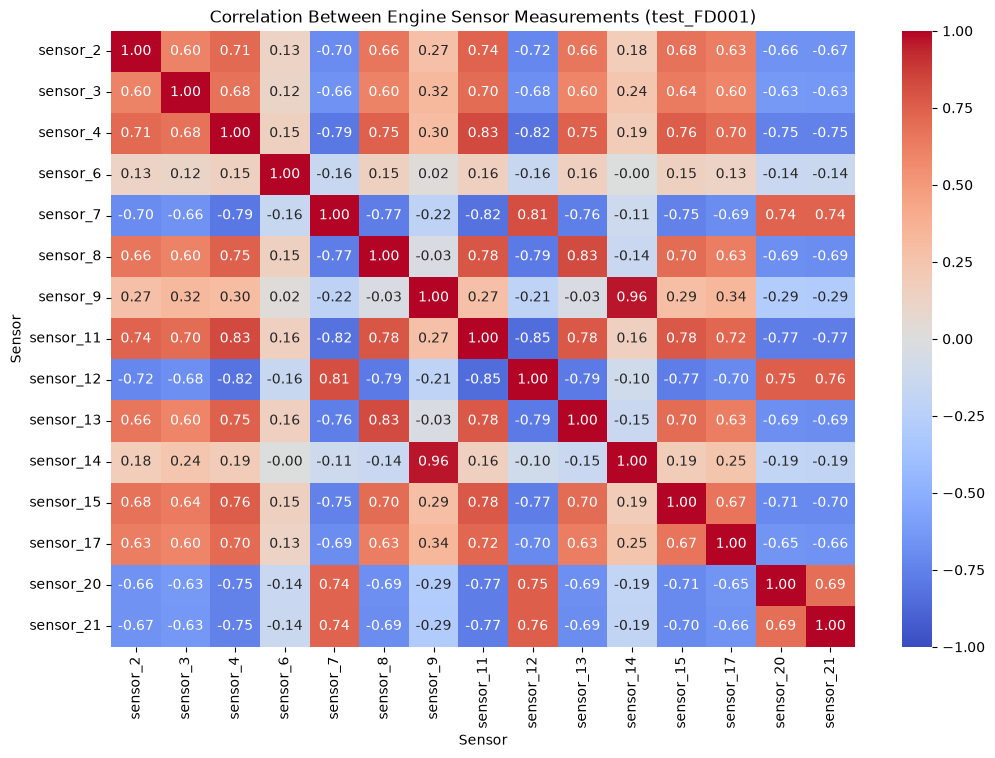

In [38]:
plt.figure(figsize=(12,8))
sns.heatmap(sensor_data_test.corr(),cmap="coolwarm", annot=True, fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Between Engine Sensor Measurements (test_FD001)")
plt.xlabel("Sensor")
plt.ylabel("Sensor")
plt.show()

In [39]:
engine1_test = df_test[df_test['engine_id'] == 1]
engine1

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,1,188,-0.0067,0.0003,100.0,643.75,1602.38,1422.78,21.61,551.94,2388.31,9037.91,48.00,519.79,2388.23,8117.69,8.5207,396,38.51,22.9588
188,1,189,-0.0006,0.0002,100.0,644.18,1596.17,1428.01,21.61,550.70,2388.27,9044.55,48.08,519.58,2388.33,8117.51,8.5183,395,38.48,23.1127
189,1,190,-0.0027,0.0001,100.0,643.64,1599.22,1425.95,21.61,551.29,2388.29,9040.58,48.33,520.04,2388.35,8112.58,8.5223,398,38.49,23.0675
190,1,191,-0.0000,-0.0004,100.0,643.34,1602.36,1425.77,21.61,550.92,2388.28,9042.76,48.15,519.57,2388.30,8114.61,8.5174,394,38.45,23.1295


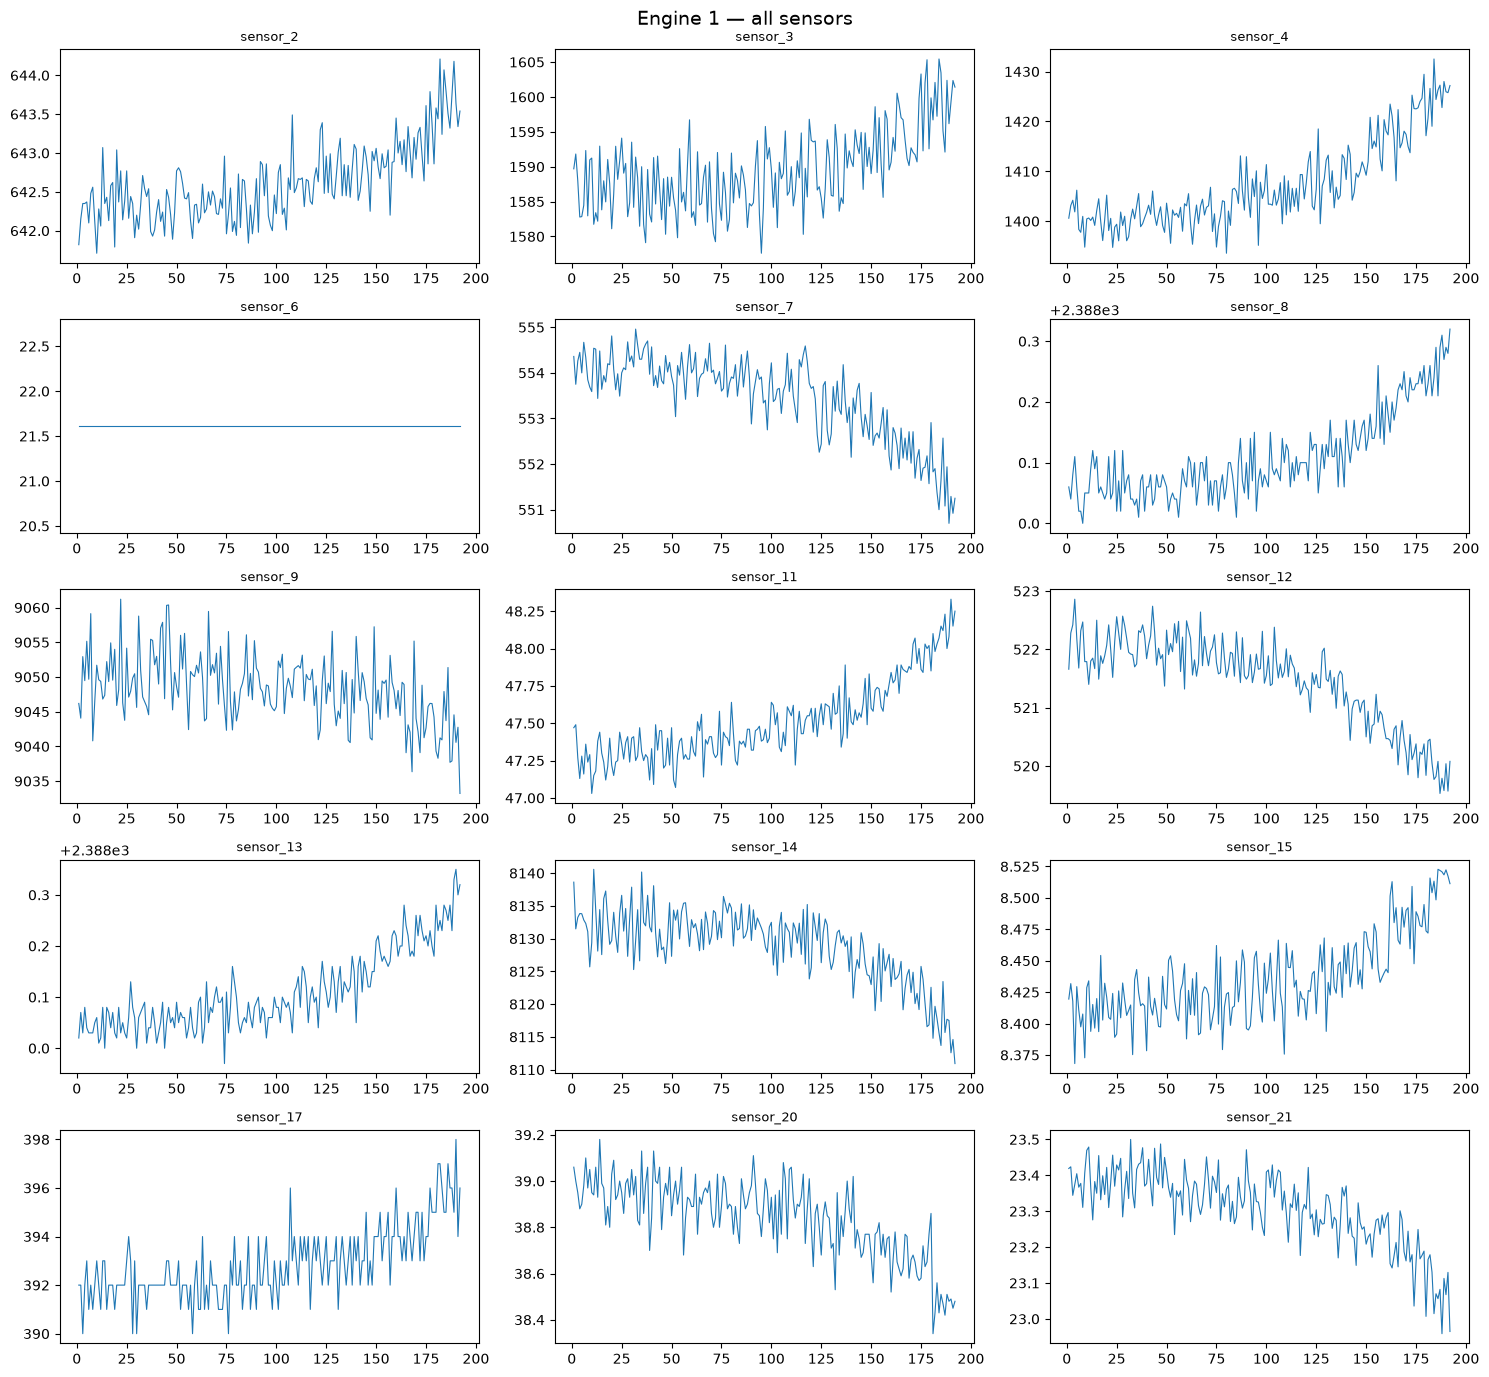

In [40]:
fig, axes = plt.subplots(5, 3, figsize=(15, 14))
for ax, s in zip(axes.flat, sensors_test):
    ax.plot(engine1_test['cycle'], engine1_test[s], linewidth=0.8)
    ax.set_title(s, fontsize=9)
fig.suptitle('Engine 1 — all sensors', fontsize=14)
plt.tight_layout()
plt.show()

In [41]:
df_test['RUL'] = df_test.groupby('engine_id')['cycle'].transform('max') - df_test['cycle']

### Rolling window features

In [42]:
WINDOW = 10

def add_rolling_features(data, sensor_columns, window=WINDOW):
    data = data.sort_values(["engine_id", "cycle"]).copy()

    for s in sensor_columns:
        data[f"{s}_roll_mean_{window}"] = (
            data.groupby('engine_id')[s]
            .transform(lambda x: x.rolling(window, min_periods=1).mean())
        )

        data[f"{s}_roll_std_{window}"] = (
            data.groupby("engine_id")[s]
            .transform(lambda x: x.rolling(window, min_periods=1).std(ddof=0))
        )

    return data

In [43]:
df = add_rolling_features(df, sensors)
test_df = add_rolling_features(df_test, sensors)

### Lag feature engineering

In [44]:
LAGS = [1, 5]

def add_lag_features(data, sensor_columns, lags=LAGS):
    data = data.sort_values(["engine_id", "cycle"]).copy()

    for sensor in sensor_columns:
        for lag in lags:
            data[f"{sensor}_lag_{lag}"] = (
                data.groupby("engine_id")[sensor].shift(lag)
            )

    return data

In [45]:
df = add_lag_features(df, sensors)
test_df = add_lag_features(df_test, sensors)

In [46]:
test_df = add_rolling_features(
    test_df,
    sensors,
    window=10
)

In [47]:
# Raw sensors plus the rolling and lag features created earlier
feature_columns = sensors + [
    column for column in df.columns
    if "_roll_" in column or "_lag_" in column
]

# The first five cycles per engine have unavailable lag values.
# Remove only those rows before scaling.
train_model = df.dropna(subset=feature_columns).copy()
test_model = test_df.dropna(subset=feature_columns).copy()

# Learn scaling values from training data only
scaler = StandardScaler()

train_model[feature_columns] = scaler.fit_transform(
    train_model[feature_columns]
)

# Apply the exact same training-based scaling to test data
test_model[feature_columns] = scaler.transform(
    test_model[feature_columns]
)

In [48]:
SEQUENCE_LENGTH = 30

def create_sequences(data, feature_columns, sequence_length=SEQUENCE_LENGTH,
                     target_column=None):
    X, y, engine_ids, end_cycles = [], [], [], []

    for engine_id, engine_data in data.groupby("engine_id"):
        engine_data = engine_data.sort_values("cycle")

        feature_values = engine_data[feature_columns].to_numpy()
        target_values = (
            engine_data[target_column].to_numpy()
            if target_column else None
        )

        for end in range(sequence_length, len(engine_data) + 1):
            start = end - sequence_length

            # Previous 30 cycles, ending at the current cycle
            X.append(feature_values[start:end])

            if target_column:
                y.append(target_values[end - 1])

            engine_ids.append(engine_id)
            end_cycles.append(engine_data["cycle"].iloc[end - 1])

    X = np.array(X)
    y = np.array(y) if target_column else None

    return X, y, np.array(engine_ids), np.array(end_cycles)

In [49]:
X_train_seq, y_train_seq, train_engine_ids, train_end_cycles = (
    create_sequences(
        train_model,
        feature_columns,
        target_column="RUL"
    )
)

In [50]:
X_test_seq, _, test_engine_ids, test_end_cycles = (
    create_sequences(
        test_model,
        feature_columns
    )
)

In [51]:
print(X_train_seq.shape)
print(y_train_seq.shape)
print(X_test_seq.shape)

(17231, 30, 75)
(17231,)
(17231, 30, 75)


In [52]:
SEQUENCE_LENGTH = 30

def create_sequences(data, feature_columns, sequence_length=SEQUENCE_LENGTH,
                     target_column=None):
    X, y, engine_ids, end_cycles = [], [], [], []

    for engine_id, engine_data in data.groupby("engine_id"):
        engine_data = engine_data.sort_values("cycle")

        values = engine_data[feature_columns].to_numpy()

        for end in range(sequence_length, len(engine_data) + 1):
            X.append(values[end - sequence_length:end])
            engine_ids.append(engine_id)
            end_cycles.append(engine_data["cycle"].iloc[end - 1])

            if target_column is not None:
                y.append(engine_data[target_column].iloc[end - 1])

    return (
        np.array(X),
        np.array(y) if target_column is not None else None,
        np.array(engine_ids),
        np.array(end_cycles)
    )

In [53]:
X_train_seq, y_train_seq, train_engine_ids, train_end_cycles = (
    create_sequences(train_model, feature_columns, target_column="RUL")
)

X_test_seq, _, test_engine_ids, test_end_cycles = (
    create_sequences(test_model, feature_columns)
)

print("Training sequences:", X_train_seq.shape)
print("Training RUL labels:", y_train_seq.shape)
print("Test sequences:", X_test_seq.shape)

Training sequences: (17231, 30, 75)
Training RUL labels: (17231,)
Test sequences: (17231, 30, 75)


In [54]:
# Convert: (samples, 30 cycles, features) → (samples, 30 × features)
X_rf = X_train_seq.reshape(X_train_seq.shape[0], -1)

# Keep every sequence from an engine in either training or validation,
# never split sequences from the same engine between both.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X_rf, y_train_seq, groups=train_engine_ids)
)

X_train_rf = X_rf[train_idx]
X_val_rf = X_rf[val_idx]

y_train_rf = y_train_seq[train_idx]
y_val_rf = y_train_seq[val_idx]

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_rf, y_train_rf)

rf_predictions = rf_model.predict(X_val_rf)

mae_rf = mean_absolute_error(y_val_rf, rf_predictions)
rmse_rf = mean_squared_error(y_val_rf, rf_predictions) ** 0.5

print(f"Random Forest MAE:  {mae_rf:.2f}")
print(f"Random Forest RMSE: {rmse_rf:.2f}")

Random Forest MAE:  17.83
Random Forest RMSE: 25.52


In [55]:
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_rf, y_train_rf)

xgb_predictions = xgb_model.predict(X_val_rf)

mae_xgb = mean_absolute_error(y_val_rf, xgb_predictions)
rmse_xgb = mean_squared_error(y_val_rf, xgb_predictions) ** 0.5

print(f"XGBoost MAE:  {mae_xgb:.2f}")
print(f"XGBoost RMSE: {rmse_xgb:.2f}")

XGBoost MAE:  17.49
XGBoost RMSE: 24.74


In [56]:
# Reuse the engine-level split created for the Random Forest model
X_train_lstm = X_train_seq[train_idx]
X_val_lstm = X_train_seq[val_idx]

y_train_lstm = y_train_seq[train_idx]
y_val_lstm = y_train_seq[val_idx]

lstm_model = Sequential([
    Input(shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),
    LSTM(64),
    Dense(32, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    validation_data=(X_val_lstm, y_val_lstm),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

lstm_predictions = lstm_model.predict(X_val_lstm).flatten()

mae_lstm = mean_absolute_error(y_val_lstm, lstm_predictions)
rmse_lstm = mean_squared_error(y_val_lstm, lstm_predictions) ** 0.5

print(f"LSTM MAE:  {mae_lstm:.2f}")
print(f"LSTM RMSE: {rmse_lstm:.2f}")

Epoch 1/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 5842.3550 - mae: 56.0639 - val_loss: 1410.3666 - val_mae: 27.9464
Epoch 2/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 1510.0096 - mae: 26.9196 - val_loss: 891.6462 - val_mae: 21.4459
Epoch 3/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 1274.0750 - mae: 24.6257 - val_loss: 887.3099 - val_mae: 22.0424
Epoch 4/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1103.3655 - mae: 22.9848 - val_loss: 859.8352 - val_mae: 20.8494
Epoch 5/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 946.5092 - mae: 21.0457 - val_loss: 746.1286 - val_mae: 19.0917
Epoch 6/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 733.6599 - mae: 18.1611 - val_loss: 870.1107 - val_mae: 20.7862
Epoch 7/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 538.5660 - mae: 15.6942 - val_loss: 701.4245 - val_mae: 18.4887
Epoch 8/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 358.5897 - mae: 12.9385 - val_loss: 882.7766 - val_mae: 19.9772
Epo

In [57]:
gru_model = Sequential([
    Input(shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),
    GRU(64),
    Dense(32, activation="relu"),
    Dense(1)
])

gru_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_gru = gru_model.fit(
    X_train_lstm,
    y_train_lstm,
    validation_data=(X_val_lstm, y_val_lstm),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

gru_predictions = gru_model.predict(X_val_lstm).flatten()

mae_gru = mean_absolute_error(y_val_lstm, gru_predictions)
rmse_gru = mean_squared_error(y_val_lstm, gru_predictions) ** 0.5

print(f"GRU MAE:  {mae_gru:.2f}")
print(f"GRU RMSE: {rmse_gru:.2f}")

Epoch 1/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 6735.0542 - mae: 61.9837 - val_loss: 1758.7491 - val_mae: 30.9886
Epoch 2/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 1717.6531 - mae: 29.5247 - val_loss: 972.0088 - val_mae: 23.5158
Epoch 3/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 1387.5125 - mae: 26.5517 - val_loss: 916.4703 - val_mae: 23.3156
Epoch 4/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 1209.1661 - mae: 24.5609 - val_loss: 936.3807 - val_mae: 22.4441
Epoch 5/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 955.7098 - mae: 21.7262 - val_loss: 938.2815 - val_mae: 22.3990
Epoch 6/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 726.7187 - mae: 18.8490 - val_loss: 818.1765 - val_mae: 20.5939
Epoch 7/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 518.7762 - mae: 15.8256 - val_loss: 1037.5990 - val_mae: 23.5030
Epoch 8/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 401.0926 - mae: 14.2635 - val_loss: 949.5427 - val_mae: 22.5320
Ep

In [58]:
bilstm_model = Sequential([
    Input(shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),
    Bidirectional(LSTM(64)),
    Dense(32, activation="relu"),
    Dense(1)
])

bilstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_bilstm = bilstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    validation_data=(X_val_lstm, y_val_lstm),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

bilstm_predictions = bilstm_model.predict(X_val_lstm).flatten()

mae_bilstm = mean_absolute_error(y_val_lstm, bilstm_predictions)
rmse_bilstm = mean_squared_error(y_val_lstm, bilstm_predictions) ** 0.5

print(f"Bidirectional LSTM MAE:  {mae_bilstm:.2f}")
print(f"Bidirectional LSTM RMSE: {rmse_bilstm:.2f}")

Epoch 1/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - loss: 4672.5171 - mae: 48.3234 - val_loss: 1124.4509 - val_mae: 25.1371
Epoch 2/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 1264.6833 - mae: 24.5362 - val_loss: 815.3151 - val_mae: 21.0296
Epoch 3/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 871.1251 - mae: 19.7796 - val_loss: 767.9441 - val_mae: 19.7406
Epoch 4/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 597.2363 - mae: 16.2739 - val_loss: 755.3760 - val_mae: 19.0125
Epoch 5/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 427.9758 - mae: 13.6810 - val_loss: 696.7726 - val_mae: 18.6256
Epoch 6/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 272.5807 - mae: 11.0850 - val_loss: 898.9587 - val_mae: 20.4233
Epoch 7/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 195.8950 - mae: 9.4611 - val_loss: 1108.4219 - val_mae: 22.0087
Epoch 8/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 134.2086 - mae: 7.9224 - val_loss: 908.5988 - val_mae: 20.311

In [59]:
cnn_lstm_model = Sequential([
    Input(shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),
    Conv1D(filters=64, kernel_size=3, activation="relu", padding="same"),
    MaxPooling1D(pool_size=2),
    LSTM(64),
    Dense(32, activation="relu"),
    Dense(1)
])

cnn_lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_cnn_lstm = cnn_lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    validation_data=(X_val_lstm, y_val_lstm),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

cnn_lstm_predictions = cnn_lstm_model.predict(X_val_lstm).flatten()

mae_cnn_lstm = mean_absolute_error(y_val_lstm, cnn_lstm_predictions)
rmse_cnn_lstm = mean_squared_error(
    y_val_lstm,
    cnn_lstm_predictions
) ** 0.5

print(f"CNN-LSTM MAE:  {mae_cnn_lstm:.2f}")
print(f"CNN-LSTM RMSE: {rmse_cnn_lstm:.2f}")

Epoch 1/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 6255.2886 - mae: 57.3216 - val_loss: 1421.8903 - val_mae: 26.3707
Epoch 2/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1429.7153 - mae: 25.0179 - val_loss: 825.0335 - val_mae: 21.3552
Epoch 3/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1045.1421 - mae: 21.1066 - val_loss: 773.5908 - val_mae: 20.5654
Epoch 4/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 701.6603 - mae: 16.5313 - val_loss: 782.2394 - val_mae: 19.5771
Epoch 5/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 501.3700 - mae: 13.8633 - val_loss: 759.8213 - val_mae: 20.2587
Epoch 6/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 364.1050 - mae: 11.7986 - val_loss: 777.2292 - val_mae: 19.9534
Epoch 7/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 211.4785 - mae: 9.2697 - val_loss: 1079.1549 - val_mae: 23.0360
Epoch 8/30
217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 154.3660 - mae: 8.1713 - val_loss: 955.6650 - val_mae: 21.6919
Epoch

In [60]:
# One input sequence → one RUL target
print("One sequence shape:", X_train_seq[0].shape)
print("RUL for its final cycle:", y_train_seq[0])

# Confirm every sequence has exactly one RUL label
assert len(X_train_seq) == len(y_train_seq)


One sequence shape: (30, 75)
RUL for its final cycle: 157


In [61]:
# Choose the best sequence model using validation MAE
sequence_models = {
    "LSTM": (lstm_model, mae_lstm),
    "GRU": (gru_model, mae_gru),
    "Bidirectional LSTM": (bilstm_model, mae_bilstm),
    "CNN-LSTM": (cnn_lstm_model, mae_cnn_lstm)
}

best_model_name = min(sequence_models, key=lambda name: sequence_models[name][1])
best_model = sequence_models[best_model_name][0]

print("Selected model:", best_model_name)

Selected model: LSTM


In [62]:
# Find the final sequence for each test engine
test_sequence_info = pd.DataFrame({
    "engine_id": test_engine_ids,
    "cycle": test_end_cycles,
    "sequence_index": np.arange(len(test_engine_ids))
})

last_sequence_indices = (
    test_sequence_info
    .sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)["sequence_index"]
    .to_numpy()
)

# Predict RUL from the latest sensor history of each test engine
X_test_final = X_test_seq[last_sequence_indices]

predicted_rul = best_model.predict(X_test_final).flatten()
predicted_rul = np.maximum(predicted_rul, 0)  # RUL cannot be negative

rul_predictions = pd.DataFrame({
    "engine_id": test_sequence_info.iloc[last_sequence_indices]["engine_id"].to_numpy(),
    "last_observed_cycle": test_sequence_info.iloc[last_sequence_indices]["cycle"].to_numpy(),
    "predicted_RUL": predicted_rul
})

rul_predictions.head()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


,engine_id,last_observed_cycle,predicted_RUL
0,1,192,3.815081
1,2,287,4.212940
2,3,179,3.662309
3,4,189,1.516214
4,5,269,4.752310


In [63]:
EARLY_FAILURE_THRESHOLD = 30  # cycles

rul_predictions["early_failure_risk"] = (
    rul_predictions["predicted_RUL"] <= EARLY_FAILURE_THRESHOLD
)

rul_predictions["risk_level"] = pd.cut(
    rul_predictions["predicted_RUL"],
    bins=[-1, 15, 30, 60, float("inf")],
    labels=["Critical", "High", "Medium", "Low"]
)

at_risk_engines = rul_predictions[
    rul_predictions["early_failure_risk"]
].sort_values("predicted_RUL")

print(f"Engines at high failure risk: {len(at_risk_engines)}")
at_risk_engines.head(10)

Engines at high failure risk: 100


,engine_id,last_observed_cycle,predicted_RUL,early_failure_risk,risk_level
54,55,193,1.318013,True,Critical
3,4,189,1.516214,True,Critical
12,13,163,2.281384,True,Critical
25,26,199,2.351203,True,Critical
33,34,195,2.405912,True,Critical
46,47,214,2.543200,True,Critical
39,40,188,2.630758,True,Critical
79,80,185,2.669027,True,Critical
69,70,137,2.877699,True,Critical
52,53,195,2.997966,True,Critical


In [64]:
sequence_info = pd.DataFrame({
    "sequence_index": np.arange(len(X_train_seq)),
    "engine_id": train_engine_ids,
    "end_cycle": train_end_cycles
})

# Last 20% of each engine's timeline becomes validation data
sequence_info["cycle_cutoff"] = (
    sequence_info.groupby("engine_id")["end_cycle"]
    .transform(lambda cycles: cycles.quantile(0.80))
)

time_train_idx = sequence_info.loc[
    sequence_info["end_cycle"] <= sequence_info["cycle_cutoff"],
    "sequence_index"
].to_numpy()

time_val_idx = sequence_info.loc[
    sequence_info["end_cycle"] > sequence_info["cycle_cutoff"],
    "sequence_index"
].to_numpy()

X_time_train = X_train_seq[time_train_idx]
y_time_train = y_train_seq[time_train_idx]

X_time_val = X_train_seq[time_val_idx]
y_time_val = y_train_seq[time_val_idx]

print("Time-series training sequences:", X_time_train.shape)
print("Time-series validation sequences:", X_time_val.shape)

Time-series training sequences: (13768, 30, 75)
Time-series validation sequences: (3463, 30, 75)


In [65]:
time_lstm_model = Sequential([
    Input(shape=(X_time_train.shape[1], X_time_train.shape[2])),
    LSTM(64),
    Dense(32, activation="relu"),
    Dense(1)
])

time_lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

time_lstm_model.fit(
    X_time_train,
    y_time_train,
    validation_data=(X_time_val, y_time_val),
    epochs=30,
    batch_size=64,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

time_predictions = time_lstm_model.predict(X_time_val).flatten()

mae_time = mean_absolute_error(y_time_val, time_predictions)
rmse_time = mean_squared_error(y_time_val, time_predictions) ** 0.5

print(f"Time-series validation MAE:  {mae_time:.2f}")
print(f"Time-series validation RMSE: {rmse_time:.2f}")

Epoch 1/30
216/216 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 7011.6870 - mae: 65.7644 - val_loss: 362.9120 - val_mae: 15.3878
Epoch 2/30
216/216 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1793.5552 - mae: 31.3534 - val_loss: 386.4006 - val_mae: 16.6811
Epoch 3/30
216/216 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1458.7490 - mae: 28.2340 - val_loss: 259.4210 - val_mae: 13.3049
Epoch 4/30
216/216 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1359.4479 - mae: 27.2017 - val_loss: 284.8142 - val_mae: 14.0886
Epoch 5/30
216/216 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1188.2393 - mae: 25.1770 - val_loss: 297.4140 - val_mae: 14.4797
Epoch 6/30
216/216 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 978.1878 - mae: 22.2834 - val_loss: 198.8463 - val_mae: 11.6456
Epoch 7/30
216/216 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 800.1285 - mae: 19.9518 - val_loss: 161.4410 - val_mae: 10.3845
Epoch 8/30
216/216 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 671.9893 - mae: 18.2821 - val_loss: 138.3607 - val_mae: 9.8624
Epoc

In [66]:
# One true RUL value per test engine, ordered by engine ID
true_test_rul = pd.read_csv(
    "RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["true_RUL"]
)

true_test_rul["engine_id"] = np.arange(1, len(true_test_rul) + 1)

evaluation_results = rul_predictions.merge(
    true_test_rul,
    on="engine_id",
    how="inner"
)

mae_test = mean_absolute_error(
    evaluation_results["true_RUL"],
    evaluation_results["predicted_RUL"]
)

print(f"Official test MAE: {mae_test:.2f}")

Official test MAE: 70.71


In [67]:
rmse_test = mean_squared_error(
    evaluation_results["true_RUL"],
    evaluation_results["predicted_RUL"]
) ** 0.5

print(f"Official test RMSE: {rmse_test:.2f}")

Official test RMSE: 82.07


In [68]:
def nasa_score(y_true, y_pred):
    error = y_pred - y_true

    scores = np.where(
        error < 0,
        np.exp(-error / 13) - 1,  # Underestimates RUL: early maintenance
        np.exp(error / 10) - 1    # Overestimates RUL: late maintenance
    )

    return scores.sum()

In [69]:
nasa_test_score = nasa_score(
    evaluation_results["true_RUL"].to_numpy(),
    evaluation_results["predicted_RUL"].to_numpy()
)

print(f"NASA-style test score: {nasa_test_score:.2f}")

NASA-style test score: 400321.81


In [73]:
rf_parameters = {
    "n_estimators": [75, 125],
    "max_depth": [10, 15],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"]
}

engine_cv = GroupKFold(n_splits=2)

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=rf_parameters,
    n_iter=3,
    scoring="neg_mean_absolute_error",
    cv=engine_cv,
    n_jobs=-1,
    random_state=42,
    verbose=2
)

rf_search.fit(
    X_rf,
    y_train_seq,
    groups=train_engine_ids
)

best_rf_model = rf_search.best_estimator_

print("Best parameters:", rf_search.best_params_)
print(f"Best validation MAE: {-rf_search.best_score_:.2f}")

Fitting 2 folds for each of 3 candidates, totalling 6 fits
Best parameters: {'n_estimators': 125, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10}
Best validation MAE: 24.95


In [74]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(best_rf_model, MODEL_DIR / "best_random_forest.joblib")
joblib.dump(scaler, MODEL_DIR / "scaler.joblib")

model_config = {
    "model_name": "Tuned Random Forest",
    "sequence_length": SEQUENCE_LENGTH,
    "feature_columns": feature_columns,
    "sensor_columns": sensors,
    "rolling_window": WINDOW,
    "lags": LAGS
}

with open(MODEL_DIR / "model_config.json", "w") as file:
    json.dump(model_config, file, indent=4)

print("Saved successfully.")

Saved successfully.


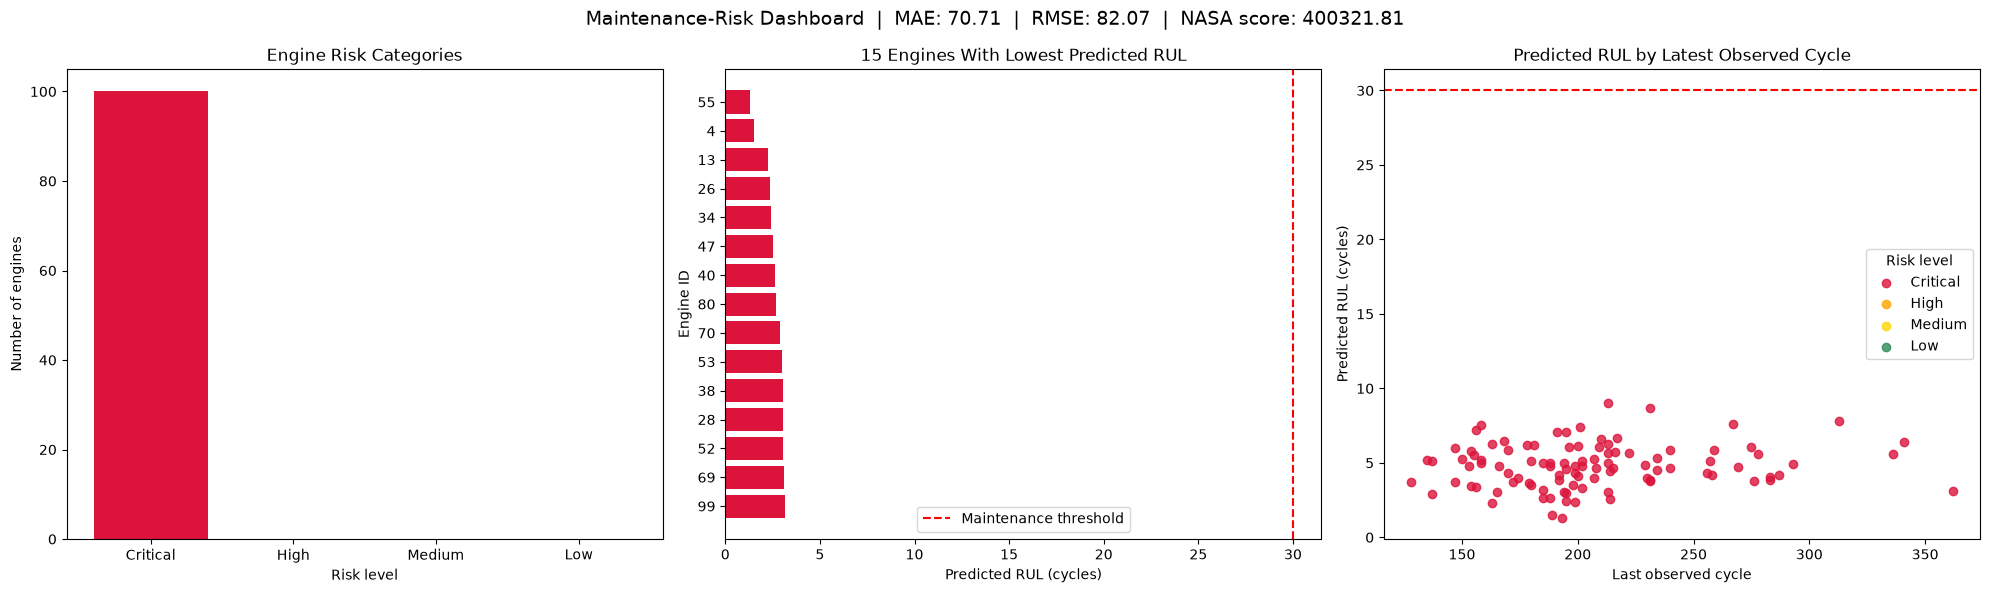

In [75]:
# Ensure each test engine has a maintenance-risk category
rul_predictions["risk_level"] = pd.cut(
    rul_predictions["predicted_RUL"],
    bins=[-1, 15, 30, 60, float("inf")],
    labels=["Critical", "High", "Medium", "Low"]
)

rul_predictions["early_failure_risk"] = (
    rul_predictions["predicted_RUL"] <= 30
)

risk_order = ["Critical", "High", "Medium", "Low"]
risk_colors = {
    "Critical": "crimson",
    "High": "orange",
    "Medium": "gold",
    "Low": "seagreen"
}

risk_counts = (
    rul_predictions["risk_level"]
    .value_counts()
    .reindex(risk_order, fill_value=0)
)

top_risk_engines = (
    rul_predictions
    .sort_values("predicted_RUL")
    .head(15)
)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Risk category count
axes[0].bar(
    risk_counts.index,
    risk_counts.values,
    color=[risk_colors[level] for level in risk_counts.index]
)
axes[0].set_title("Engine Risk Categories")
axes[0].set_xlabel("Risk level")
axes[0].set_ylabel("Number of engines")

# Most urgent engines
axes[1].barh(
    top_risk_engines["engine_id"].astype(str),
    top_risk_engines["predicted_RUL"],
    color=[
        risk_colors[level]
        for level in top_risk_engines["risk_level"]
    ]
)
axes[1].axvline(
    30,
    color="red",
    linestyle="--",
    label="Maintenance threshold"
)
axes[1].set_title("15 Engines With Lowest Predicted RUL")
axes[1].set_xlabel("Predicted RUL (cycles)")
axes[1].set_ylabel("Engine ID")
axes[1].invert_yaxis()
axes[1].legend()

# Lifecycle position compared with predicted RUL
for level in risk_order:
    subset = rul_predictions[rul_predictions["risk_level"] == level]

    axes[2].scatter(
        subset["last_observed_cycle"],
        subset["predicted_RUL"],
        label=level,
        color=risk_colors[level],
        alpha=0.8
    )

axes[2].axhline(30, color="red", linestyle="--")
axes[2].set_title("Predicted RUL by Latest Observed Cycle")
axes[2].set_xlabel("Last observed cycle")
axes[2].set_ylabel("Predicted RUL (cycles)")
axes[2].legend(title="Risk level")

fig.suptitle(
    f"Maintenance-Risk Dashboard  |  "
    f"MAE: {mae_test:.2f}  |  "
    f"RMSE: {rmse_test:.2f}  |  "
    f"NASA score: {nasa_test_score:.2f}",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [76]:
def predict_engine_rul(
    engine_data,
    model,
    feature_columns,
    sequence_length=SEQUENCE_LENGTH
):
    engine_data = engine_data.sort_values("cycle")

    if len(engine_data) < sequence_length:
        raise ValueError(
            f"At least {sequence_length} cycles are required "
            "to make a prediction."
        )

    latest_sequence = (
        engine_data[feature_columns]
        .tail(sequence_length)
        .to_numpy()
    )

    # Random Forest requires one flattened row
    latest_sequence_flat = latest_sequence.reshape(1, -1)

    predicted_rul = model.predict(latest_sequence_flat)[0]

    return max(predicted_rul, 0)

In [78]:
engine_id_to_predict = 2

engine_data = test_model[
    test_model["engine_id"] == engine_id_to_predict
]

engine_rul_prediction = predict_engine_rul(
    engine_data=engine_data,
    model=best_rf_model,
    feature_columns=feature_columns
)

print(
    f"Predicted remaining useful life for "
    f"Engine {engine_id_to_predict}: "
    f"{engine_rul_prediction:.2f} cycles"
)

Predicted remaining useful life for Engine 2: 2.15 cycles
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=125; total time=  18.0s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=125; total time=  18.0s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=75; total time=  10.7s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=75; total time=   9.5s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=125; total time=  18.0s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=125; total time=  16.0s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=75; total time=  12.4s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=125; tota